# Hydrogen-bond RDFs at 300 K

All ring C--H donors are pooled. Black dashed curves are the AIMD references from Brela et al.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

chapter = Path.cwd().resolve()
if chapter.name == 'notebooks':
    chapter = chapter.parent
data = pd.read_csv(chapter / 'data' / 'hbond_rdfs_300K.csv')
colours = {'APPLE&P': '#0077BB', 'SO3LR': '#EE7733', 'CL&P': '#009988', 'CL&P-scaled': '#CC3311'}
order = ['SO3LR', 'APPLE&P', 'CL&P', 'CL&P-scaled']
plt.rcParams.update({'font.size': 14, 'font.family': 'sans-serif', 'axes.labelsize': 16, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'axes.linewidth': 1.5, 'lines.linewidth': 2.0})


/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)
/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


PosixPath('/gpfs/home5/akryachkova/emimntf2-paper-repro/04_hydrogen_bonds/figures/hbond_rdfs_300K.png')

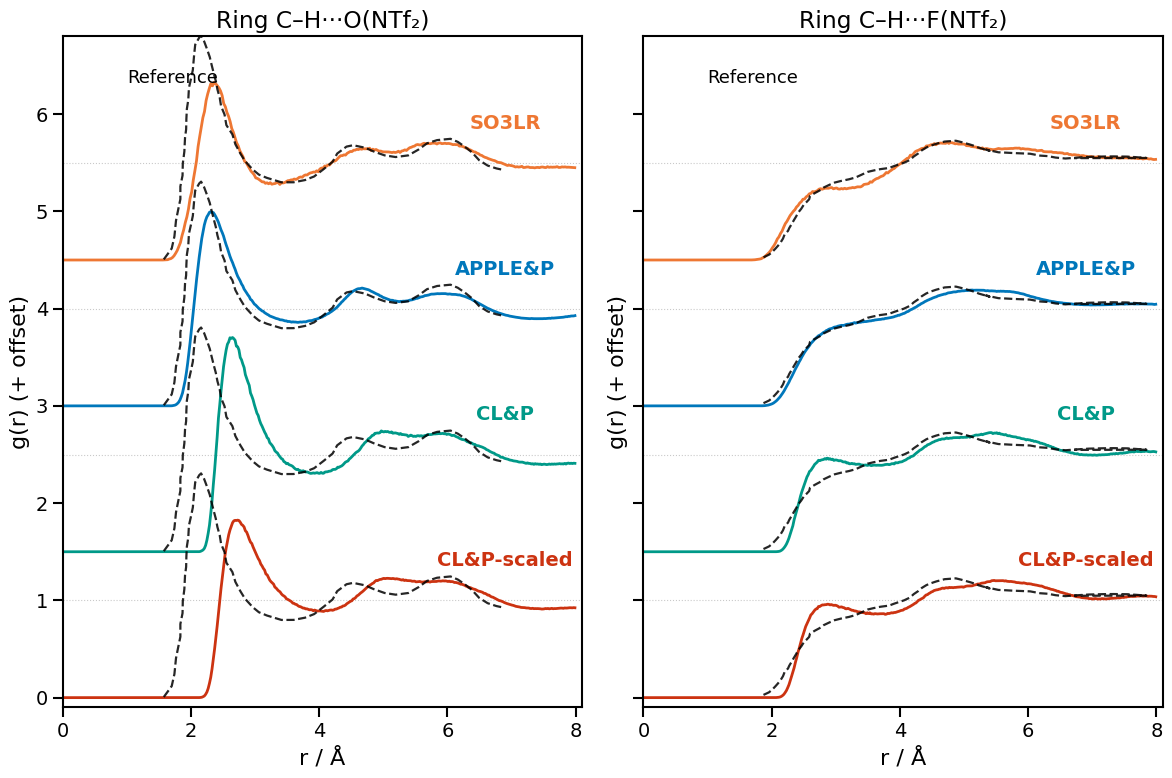

In [3]:
def read_reference(name):
    reference = pd.read_csv(chapter / 'reference_data' / name)
    return reference.iloc[:, 0], reference.iloc[:, 1]

def plot_panel(ax, pair, reference_name, title):
    r_ref, g_ref = read_reference(reference_name)
    offset_step = 1.5
    for i, force_field in enumerate(order):
        curve = data[(data.force_field == force_field) & (data.pair == pair)].sort_values('r_A')
        offset = (len(order) - 1 - i) * offset_step
        ax.axhline(offset + 1, color='0.65', lw=0.8, ls=':', alpha=0.6)
        ax.plot(curve.r_A, curve.g_r + offset, color=colours[force_field])
        ax.plot(r_ref, g_ref + offset, color='black', lw=1.6, ls='--', alpha=0.85)
        ax.text(6.9, offset + 1.35, force_field, color=colours[force_field], fontsize=14, fontweight='bold', ha='center')
    ax.set(xlim=(0, 8.1), ylim=(-0.1, 6.8), xlabel='r / Å', ylabel='g(r) (+ offset)', title=title)
    ax.text(1.0, 6.32, 'Reference', color='black', fontsize=13)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    ax.tick_params(width=1.5, length=7)

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
plot_panel(axes[0], 'H_O', 'O-Hbond.csv', 'Ring C–H···O(NTf₂)')
plot_panel(axes[1], 'H_F', 'O-Fbond.csv', 'Ring C–H···F(NTf₂)')
fig.tight_layout()
output = chapter / 'figures' / 'hbond_rdfs_300K.png'
output.parent.mkdir(exist_ok=True)
fig.savefig(output, dpi=300, bbox_inches='tight', facecolor='white')
output
